# Practical Session 3 - Hypothesis spaces, feature representations and model generalization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

## Part A - Hypothesis spaces

(10, 3)
          Hours      Score
count  10.00000  10.000000
mean    5.50000  67.900000
std     3.02765  16.907921
min     1.00000  42.000000
25%     3.25000  56.000000
50%     5.50000  68.000000
75%     7.75000  80.250000
max    10.00000  91.000000


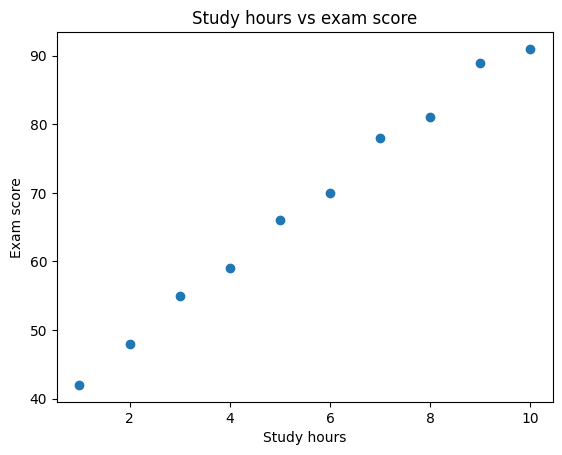

In [2]:
df = pd.DataFrame({
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10"],
    "Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Score": [42, 48, 55, 59, 66, 70, 78, 81, 89, 91],
})
print(df.shape)
print(df.describe())

X = df[["Hours"]].values
y = df["Score"].values

plt.scatter(X, y)
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Study hours vs exam score")
plt.show()

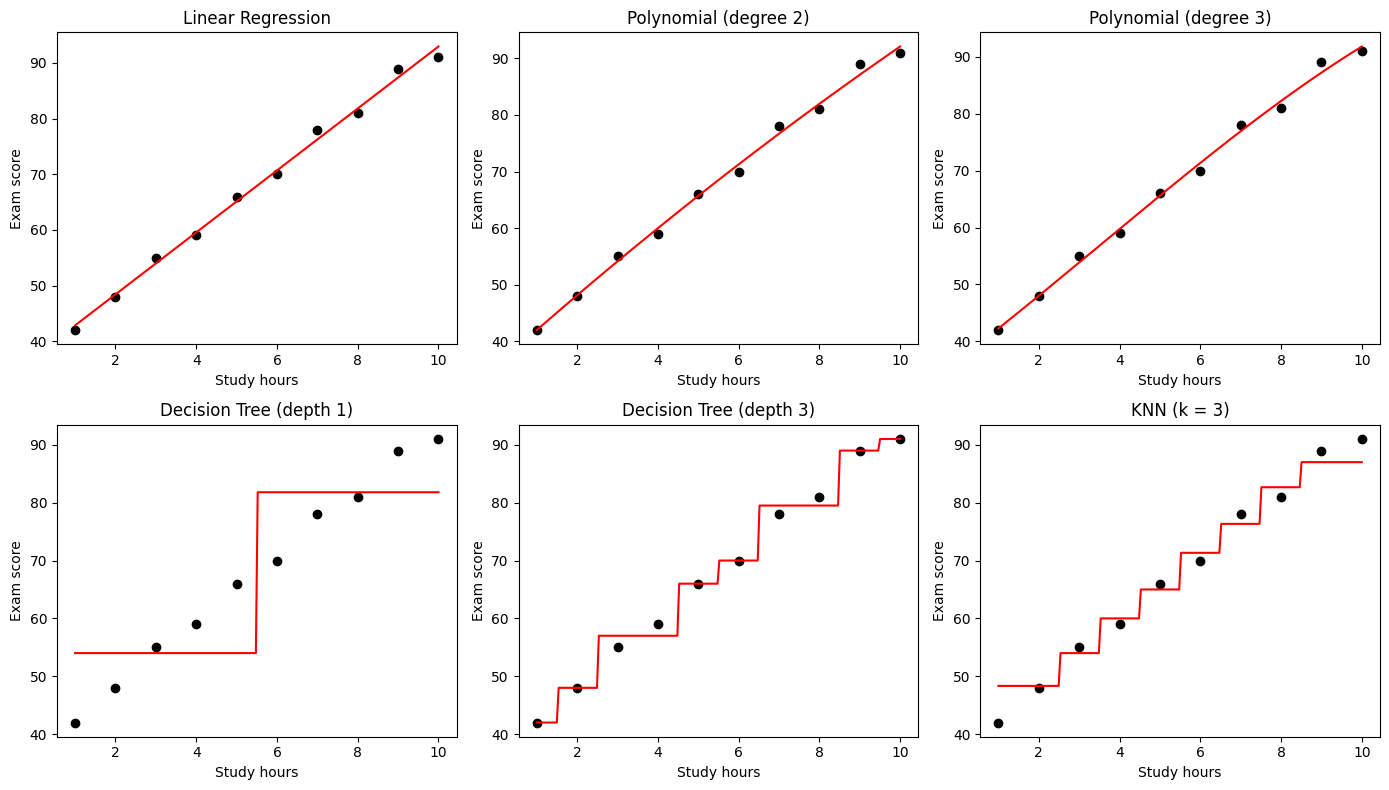

                     Model  Training RMSE  Training R2
0        Linear Regression          1.167        0.995
1    Polynomial (degree 2)          1.044        0.996
2    Polynomial (degree 3)          1.021        0.996
3  Decision Tree (depth 1)          8.005        0.751
4  Decision Tree (depth 3)          1.118        0.995
5              KNN (k = 3)          2.656        0.973


In [3]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial (degree 2)": make_pipeline(PolynomialFeatures(2), LinearRegression()),
    "Polynomial (degree 3)": make_pipeline(PolynomialFeatures(3), LinearRegression()),
    "Decision Tree (depth 1)": DecisionTreeRegressor(max_depth=1, random_state=42),
    "Decision Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=42),
    "KNN (k = 3)": KNeighborsRegressor(n_neighbors=3),
}

x_grid = np.linspace(1, 10, 200).reshape(-1, 1)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
results_a = []
for ax, (name, model) in zip(axes.flatten(), models.items()):
    model.fit(X, y)
    pred = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, pred))
    r2 = r2_score(y, pred)
    results_a.append([name, round(rmse, 3), round(r2, 3)])
    ax.scatter(X, y, color="black")
    ax.plot(x_grid, model.predict(x_grid), color="red")
    ax.set_title(name)
    ax.set_xlabel("Study hours")
    ax.set_ylabel("Exam score")
plt.tight_layout()
plt.show()

table_a = pd.DataFrame(results_a, columns=["Model", "Training RMSE", "Training R2"])
print(table_a)

**Observations (Part A).** The linear regression gives a straight line that follows the points well (training RMSE 1.167). The polynomial models of degree 2 and 3 give a line with a very small curve, almost the same as the linear one; their training RMSE is a little lower (1.044 and 1.021) because they are more flexible. The decision trees and KNN give step curves (constant values by region). The tree with depth 1 has only two levels, so it fits badly (RMSE 8.005, R2 0.751). The tree with depth 3 follows the points much better (RMSE 1.118), and KNN with k = 3 is in between (RMSE 2.656). So the data is almost linear, and the models with a linear shape represent the relationship in the most natural way. A good training RMSE alone does not tell if the model generalizes, which is checked in Part B.

## Part B - Model complexity and generalization

In [4]:
loo = LeaveOneOut()
for i, (train_idx, test_idx) in enumerate(loo.split(X)):
    print("Iteration", i + 1)
    print("  Train indices:", train_idx)
    print("  Test index:", test_idx)

Iteration 1
  Train indices: [1 2 3 4 5 6 7 8 9]
  Test index: [0]
Iteration 2
  Train indices: [0 2 3 4 5 6 7 8 9]
  Test index: [1]
Iteration 3
  Train indices: [0 1 3 4 5 6 7 8 9]
  Test index: [2]
Iteration 4
  Train indices: [0 1 2 4 5 6 7 8 9]
  Test index: [3]
Iteration 5
  Train indices: [0 1 2 3 5 6 7 8 9]
  Test index: [4]
Iteration 6
  Train indices: [0 1 2 3 4 6 7 8 9]
  Test index: [5]
Iteration 7
  Train indices: [0 1 2 3 4 5 7 8 9]
  Test index: [6]
Iteration 8
  Train indices: [0 1 2 3 4 5 6 8 9]
  Test index: [7]
Iteration 9
  Train indices: [0 1 2 3 4 5 6 7 9]
  Test index: [8]
Iteration 10
  Train indices: [0 1 2 3 4 5 6 7 8]
  Test index: [9]


   Polynomial Degree  Training RMSE  LOOCV RMSE
0                  1          1.167       1.549
1                  2          1.044       1.573
2                  3          1.021       2.062
3                  5          0.894       3.707
4                  9          0.000     222.163
Lowest LOOCV RMSE: degree 1 with 1.549


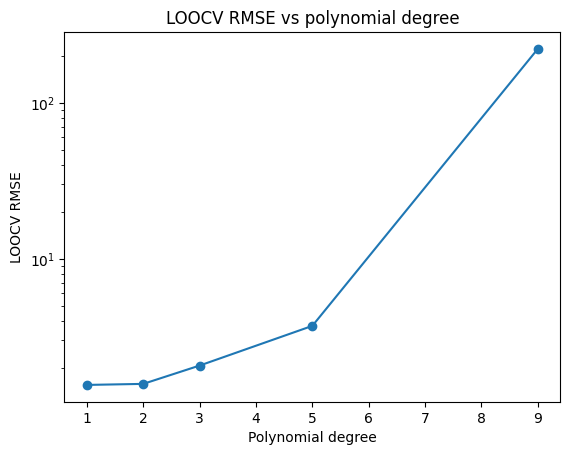

In [5]:
def train_rmse(model):
    model.fit(X, y)
    return np.sqrt(mean_squared_error(y, model.predict(X)))

def loocv_rmse(model):
    scores = cross_val_score(model, X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    return np.sqrt(-scores.mean())

def poly_model(degree, regressor):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), regressor)

degrees = [1, 2, 3, 5, 9]
results_b = []
for d in degrees:
    model = poly_model(d, LinearRegression())
    results_b.append([d, round(train_rmse(model), 3), round(loocv_rmse(model), 3)])

table_b = pd.DataFrame(results_b, columns=["Polynomial Degree", "Training RMSE", "LOOCV RMSE"])
print(table_b)

best_row = table_b.loc[table_b["LOOCV RMSE"].idxmin()]
print("Lowest LOOCV RMSE: degree", int(best_row["Polynomial Degree"]), "with", best_row["LOOCV RMSE"])

plt.plot(table_b["Polynomial Degree"], table_b["LOOCV RMSE"], marker="o")
plt.xlabel("Polynomial degree")
plt.ylabel("LOOCV RMSE")
plt.title("LOOCV RMSE vs polynomial degree")
plt.yscale("log")
plt.show()

## Part C - Feature representation and regularization

In [6]:
results_c1 = []
for name, d in [("Original (x)", 1), ("x, x2, x3", 3), ("x, ..., x5", 5)]:
    model = poly_model(d, LinearRegression())
    results_c1.append([name, round(loocv_rmse(model), 3)])
print(pd.DataFrame(results_c1, columns=["Representation", "LOOCV RMSE"]))

  Representation  LOOCV RMSE
0   Original (x)       1.549
1      x, x2, x3       2.062
2     x, ..., x5       3.707


In [7]:
alphas = [0.01, 0.1, 1, 10]
results_c2 = []
for d in [3, 5]:
    for alpha in alphas:
        ridge = poly_model(d, Ridge(alpha=alpha))
        lasso = poly_model(d, Lasso(alpha=alpha, max_iter=100000))
        results_c2.append(["Ridge", d, alpha, round(loocv_rmse(ridge), 3)])
        results_c2.append(["Lasso", d, alpha, round(loocv_rmse(lasso), 3)])
table_c2 = pd.DataFrame(results_c2, columns=["Model", "Degree", "Alpha", "LOOCV RMSE"])
print(table_c2)

deg5 = table_c2[table_c2["Degree"] == 5]
best_ridge = deg5[deg5["Model"] == "Ridge"].sort_values("LOOCV RMSE").iloc[0]
best_lasso = deg5[deg5["Model"] == "Lasso"].sort_values("LOOCV RMSE").iloc[0]

    Model  Degree  Alpha  LOOCV RMSE
0   Ridge       3   0.01       1.708
1   Lasso       3   0.01       1.589
2   Ridge       3   0.10       1.843
3   Lasso       3   0.10       1.587
4   Ridge       3   1.00       3.753
5   Lasso       3   1.00       1.919
6   Ridge       3  10.00       6.503
7   Lasso       3  10.00      11.877
8   Ridge       5   0.01       2.144
9   Lasso       5   0.01       1.765
10  Ridge       5   0.10       1.807
11  Lasso       5   0.10       1.622
12  Ridge       5   1.00       3.574
13  Lasso       5   1.00       1.919
14  Ridge       5  10.00       7.282
15  Lasso       5  10.00      11.877


In [8]:
rows_c3 = [
    ["Linear Regression", 1, "None", loocv_rmse(poly_model(1, LinearRegression()))],
    ["Polynomial Regression", 3, "None", loocv_rmse(poly_model(3, LinearRegression()))],
    ["Polynomial Regression", 5, "None", loocv_rmse(poly_model(5, LinearRegression()))],
    ["Ridge Regression (alpha=%s)" % best_ridge["Alpha"], 5, "L2", best_ridge["LOOCV RMSE"]],
    ["Lasso Regression (alpha=%s)" % best_lasso["Alpha"], 5, "L1", best_lasso["LOOCV RMSE"]],
    ["Decision Tree (depth 1)", "-", "None", loocv_rmse(DecisionTreeRegressor(max_depth=1, random_state=42))],
    ["Decision Tree (depth 3)", "-", "None", loocv_rmse(DecisionTreeRegressor(max_depth=3, random_state=42))],
    ["KNN (k = 3)", "-", "None", loocv_rmse(KNeighborsRegressor(n_neighbors=3))],
]
table_c3 = pd.DataFrame(rows_c3, columns=["Model", "Feature Degree", "Regularization", "LOOCV RMSE"])
table_c3["LOOCV RMSE"] = table_c3["LOOCV RMSE"].round(3)
print(table_c3)

poly5 = table_c3.iloc[2]["LOOCV RMSE"]
print("Poly degree 5 without regularization:", poly5)
print("Ridge degree 5:", best_ridge["LOOCV RMSE"])
print("Lasso degree 5:", best_lasso["LOOCV RMSE"])

                          Model Feature Degree Regularization  LOOCV RMSE
0             Linear Regression              1           None       1.549
1         Polynomial Regression              3           None       2.062
2         Polynomial Regression              5           None       3.707
3  Ridge Regression (alpha=0.1)              5             L2       1.807
4  Lasso Regression (alpha=0.1)              5             L1       1.622
5       Decision Tree (depth 1)              -           None      13.458
6       Decision Tree (depth 3)              -           None       6.366
7                   KNN (k = 3)              -           None       6.004
Poly degree 5 without regularization: 3.707
Ridge degree 5: 1.807
Lasso degree 5: 1.622


## Part D - Final model comparison

                          Model  Training RMSE  LOOCV RMSE
0             Linear Regression          1.167       1.549
1         Polynomial (degree 2)          1.044       1.573
2  Ridge (degree 3, alpha=0.01)          1.022       1.708
3   Lasso (degree 3, alpha=0.1)          1.159       1.587
4       Decision Tree (depth 3)          1.118       6.366
5                   KNN (k = 3)          2.656       6.004


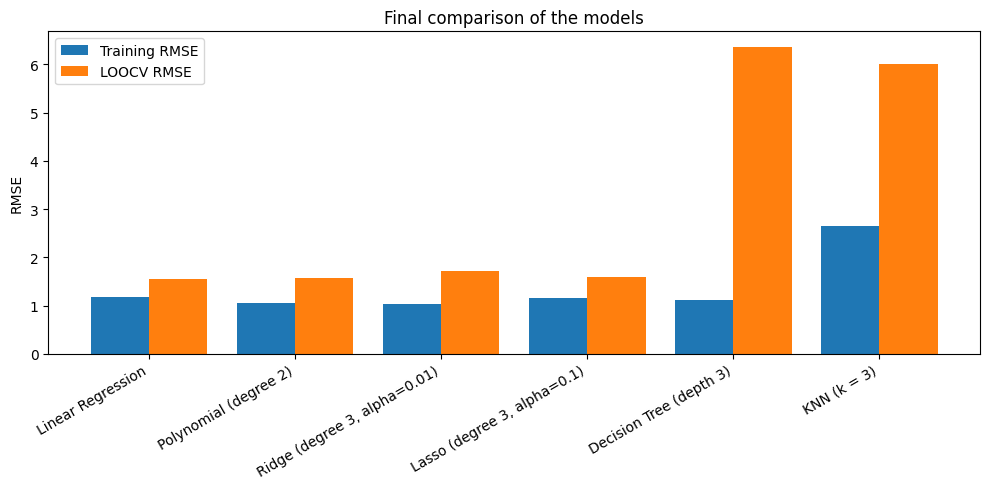

In [9]:
best_poly_degree = table_b[table_b["Polynomial Degree"] > 1].sort_values("LOOCV RMSE").iloc[0]["Polynomial Degree"]
best_poly_degree = int(best_poly_degree)

best_ridge_all = table_c2[table_c2["Model"] == "Ridge"].sort_values("LOOCV RMSE").iloc[0]
best_lasso_all = table_c2[table_c2["Model"] == "Lasso"].sort_values("LOOCV RMSE").iloc[0]

tree_depths = [1, 3]
best_depth = min(tree_depths, key=lambda d: loocv_rmse(DecisionTreeRegressor(max_depth=d, random_state=42)))

final_models = {
    "Linear Regression": poly_model(1, LinearRegression()),
    "Polynomial (degree %d)" % best_poly_degree: poly_model(best_poly_degree, LinearRegression()),
    "Ridge (degree %d, alpha=%s)" % (best_ridge_all["Degree"], best_ridge_all["Alpha"]): poly_model(int(best_ridge_all["Degree"]), Ridge(alpha=best_ridge_all["Alpha"])),
    "Lasso (degree %d, alpha=%s)" % (best_lasso_all["Degree"], best_lasso_all["Alpha"]): poly_model(int(best_lasso_all["Degree"]), Lasso(alpha=best_lasso_all["Alpha"], max_iter=100000)),
    "Decision Tree (depth %d)" % best_depth: DecisionTreeRegressor(max_depth=best_depth, random_state=42),
    "KNN (k = 3)": KNeighborsRegressor(n_neighbors=3),
}

rows_d = []
for name, model in final_models.items():
    rows_d.append([name, round(train_rmse(model), 3), round(loocv_rmse(model), 3)])
table_d = pd.DataFrame(rows_d, columns=["Model", "Training RMSE", "LOOCV RMSE"])
print(table_d)

pos = np.arange(len(table_d))
plt.figure(figsize=(10, 5))
plt.bar(pos - 0.2, table_d["Training RMSE"], width=0.4, label="Training RMSE")
plt.bar(pos + 0.2, table_d["LOOCV RMSE"], width=0.4, label="LOOCV RMSE")
plt.xticks(pos, table_d["Model"], rotation=30, ha="right")
plt.ylabel("RMSE")
plt.title("Final comparison of the models")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

**Model complexity.** When the complexity increases, the training RMSE decreases (1.167 for degree 1 and 0.000 for degree 9), but the LOOCV RMSE gets worse (1.549 for degree 1 and 222.163 for degree 9). The degree 9 model passes through all the training points, so it overfits. The data is almost linear, so the simplest model, linear regression, generalizes best.

**Feature representation.** Adding more polynomial features did not help: the LOOCV RMSE went from 1.549 (x) to 2.062 (x, x2, x3) and 3.707 (up to x5).

**Regularization.** Ridge and Lasso improve the degree 5 polynomial (LOOCV RMSE from 3.707 to 1.807 with Ridge and 1.622 with Lasso), because they limit the size of the coefficients. But they do not beat the simple linear regression (1.549). A big alpha (10) gives underfitting (RMSE of 7.282 for Ridge and 11.877 for Lasso).

**Decision tree and KNN.** They fit the training data well (the tree with depth 3 has a training RMSE of 1.118) but have a bad LOOCV RMSE (6.366 for the tree and 6.004 for KNN). They predict constant values by region, so they cannot follow the straight trend of the data, and KNN makes its biggest errors on the first and last students.

**Final result.** The best model is Linear Regression with a LOOCV RMSE of 1.549, followed closely by the degree 2 polynomial (1.573) and by Lasso (1.587). A more complex model is not always better, and what matters is the performance on unseen data.